# arXiv embeddings at scale

This notebook consumes the sample and text-vector cache made by [Prepare the arXiv dataset](../data/arxiv/prepare_arxiv_dataset.ipynb). It fits one UMAP embedding and one multilevel-initialized IMSTE embedding with an integrated density-gravity phase. The estimator can return both the pre-gravity and final gravity coordinates. Gravity is feature-space based; UMAP coordinates are never used to initialize IMSTE.


## 1. Load the prepared dataset

Run `../data/arxiv/prepare_arxiv_dataset.ipynb` first if there is no cache or if you want a larger sample. Here, increasing or changing model settings does not download or re-embed text; this notebook reads the one prepared cache.

In [33]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
for local_path in (PROJECT_ROOT, PROJECT_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)
import imste
if not Path(imste.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()):
    raise RuntimeError(
        f"This kernel already loaded IMSTE from {imste.__file__}; restart the kernel and rerun from the top."
    )
DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
from arxiv_dataset import load_arxiv_dataset
papers, X, data_manifest = load_arxiv_dataset(DATA_DIR)
papers_all, X_all = papers.copy(), X  # Keep the loaded cache intact when re-running the sampling cell.
print(f"Loaded {len(papers):,} papers × {X.shape[1]:,} features")
print(f"Vector matrix in memory: {X.nbytes / 1024**3:.2f} GiB")
print("Dataset cache ID:", data_manifest["dataset_id"])


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Loaded 3,233,620 papers × 384 features
Vector matrix in memory: 4.63 GiB
Dataset cache ID: 6279205cb3ce7d1bf8df


## 2. Prepare category labels

In [34]:
# Set this to a positive integer to cap each domain, or None to use all papers.
MAX_PAPERS_PER_DOMAIN = 20_000

# Start from the prepared cache each time this cell runs.
papers, X = papers_all.copy(), X_all
primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")

original_n_papers = len(papers)
if MAX_PAPERS_PER_DOMAIN is not None:
    if not isinstance(MAX_PAPERS_PER_DOMAIN, int) or MAX_PAPERS_PER_DOMAIN < 1:
        raise ValueError("MAX_PAPERS_PER_DOMAIN must be a positive integer or None.")

    rng = np.random.default_rng(int(data_manifest["random_state"]))
    domain_values = domain.to_numpy()
    selected = []
    for domain_name in pd.unique(domain_values):
        domain_indices = np.flatnonzero(domain_values == domain_name)
        n_selected = min(len(domain_indices), MAX_PAPERS_PER_DOMAIN)
        selected.append(rng.choice(domain_indices, size=n_selected, replace=False))
    selected_indices = np.sort(np.concatenate(selected))

    papers = papers.iloc[selected_indices].reset_index(drop=True)
    X = X[selected_indices]
    primary_category = primary_category.iloc[selected_indices].reset_index(drop=True)
    domain = domain.iloc[selected_indices].reset_index(drop=True)

    # Distinguish this sampled subset from the full dataset in the projection cache.
    import hashlib
    subset_hash = hashlib.sha256(selected_indices.astype(np.int64).tobytes()).hexdigest()[:16]
    projection_dataset_id = f"{data_manifest['dataset_id']}-domain-cap-{MAX_PAPERS_PER_DOMAIN}-{subset_hash}"
else:
    projection_dataset_id = data_manifest["dataset_id"]

domain_order = domain.value_counts().index.tolist()
labels = pd.Categorical(domain, categories=domain_order)
print(f"Using {len(papers):,} of {original_n_papers:,} papers (max {MAX_PAPERS_PER_DOMAIN} per domain).")
display(pd.DataFrame({"primary_category": primary_category, "domain": domain}).groupby("domain", observed=True).size().sort_values(ascending=False).rename("papers"))


Using 147,040 of 3,233,620 papers (max 20000 per domain).


domain
biology             20000
computer science    20000
engineering         20000
mathematics         20000
physics             20000
statistics          20000
finance             13876
economics           13164
Name: papers, dtype: int64

## 3. Fit recursively initialized UMAP and multilevel IMSTE with gravity

UMAP uses its recursive multilevel initialization (`init="recursive"`). Set the UMAP and IMSTE parameters below. Gravity is an estimator phase, configured with `IMSTE_GRAVITY_*`, and runs inside `fit_transform`. `fit_transform(X, return_intermediate=True)` returns both the pre-gravity coordinates and the final coordinates. RINND and Leiden build feature-space regions; labels are used only for rendering. UMAP coordinates do not initialize IMSTE.


In [40]:
import umap
from arxiv_imste import prepare_arxiv_projection_cache

RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"  # or "cosine"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
UMAP_REPULSION_STRENGTH = 2
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": UMAP_REPULSION_STRENGTH,
    "metric": METRIC,
    "init": "recursive",
    "recursive_coarsening_ratio": 4,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
    "verbose": True,
}

# IMSTE embedding and optimizer
IMSTE_N_COMPONENTS = 2  # The comparison renderer displays the first two.
IMSTE_N_MSTS = 5
IMSTE_N_EPOCHS = 1000
IMSTE_BATCH_SIZE = 32768*4
IMSTE_LEARNING_RATE = 0.05
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.5
IMSTE_EPSILON = 1e-4
IMSTE_LOGISTIC_MARGIN = 1.0
IMSTE_LOGISTIC_TEMPERATURE = 0.5
IMSTE_RANDOM_STATE = RANDOM_STATE
IMSTE_DEVICE = "mps"  # "auto", "cpu", or "mps"
IMSTE_VERBOSE = True
IMSTE_FORCE_REFIT = False  # True refits IMSTE without refitting UMAP.

# MST graph construction
IMSTE_MST_METHOD = "famst"  # "famst" or "prim"
IMSTE_MST_NEIGHBOR_BACKEND = "auto"  # "auto", "rinnd", "pynndescent", or "mps_exact"
IMSTE_MST_NEIGHBORS = 15
IMSTE_MST_INTER_COMPONENT_EDGES = 5
IMSTE_MST_MAX_NEIGHBORS = None
IMSTE_MST_REPRESENTATIVES_PER_COMPONENT = 10

# Initialization and multilevel fitting
IMSTE_PCA_INIT = True
IMSTE_PCA_INIT_SCALING = "global"  # "global" or "none"
IMSTE_INIT_COORDINATES = None  # Optional (n_samples, n_components) array
IMSTE_MULTILEVEL_INIT = True
IMSTE_MULTILEVEL_REDUCTION_RATIO = 8
IMSTE_MULTILEVEL_BASE_SIZE = 512
IMSTE_MULTILEVEL_EPOCHS = 20

# Optional gravity second phase (Euclidean feature graph; no UMAP initialization)
IMSTE_GRAVITY_ENABLED = True
IMSTE_GRAVITY_MODE = "mexican_hat"  # "mexican_hat" or "density_core"
IMSTE_GRAVITY_STRENGTH = 0.3  # Pull toward density-weighted Leiden region cores.
IMSTE_GRAVITY_RESOLUTION = 0.8
IMSTE_GRAVITY_CORE_QUANTILE = 0.95  # Defines each Leiden region's density core.
IMSTE_GRAVITY_MASS_POWER = 0.5
IMSTE_GRAVITY_NEIGHBORS = 15
# Mexican-hat region-center force: near regions repel, middle distances attract.
IMSTE_GRAVITY_ATTRACTION_STRENGTH = 0.5
IMSTE_GRAVITY_NEAR_REPULSION_STRENGTH = 0.5
IMSTE_GRAVITY_FORCE_NEIGHBORS = 8
IMSTE_GRAVITY_ATTRACTION_RANGE = 1.0  # × each point's local 2D neighbor radius
IMSTE_GRAVITY_REPULSION_RANGE = 0.5  # very local; × each point's neighbor radius
IMSTE_GRAVITY_STEP_SIZE = 0.05
IMSTE_GRAVITY_ITERATIONS = 3
IMSTE_GRAVITY_PACK_REGIONS = False
IMSTE_GRAVITY_PACK_RADIUS_QUANTILE = 0.9
IMSTE_GRAVITY_PACK_GAP_FRACTION = 0.25
imste_settings = {
    "n_components": IMSTE_N_COMPONENTS,
    "n_msts": IMSTE_N_MSTS,
    "n_epochs": IMSTE_N_EPOCHS,
    "batch_size": IMSTE_BATCH_SIZE,
    "learning_rate": IMSTE_LEARNING_RATE,
    "negative_ratio": IMSTE_NEGATIVE_RATIO,
    "lambda_rep": IMSTE_LAMBDA_REP,
    "random_state": IMSTE_RANDOM_STATE,
    "epsilon": IMSTE_EPSILON,
    "device": IMSTE_DEVICE,
    "logistic_margin": IMSTE_LOGISTIC_MARGIN,
    "logistic_temperature": IMSTE_LOGISTIC_TEMPERATURE,
    "mst_method": IMSTE_MST_METHOD,
    "mst_neighbor_backend": IMSTE_MST_NEIGHBOR_BACKEND,
    "mst_neighbors": IMSTE_MST_NEIGHBORS,
    "mst_inter_component_edges": IMSTE_MST_INTER_COMPONENT_EDGES,
    "mst_max_neighbors": IMSTE_MST_MAX_NEIGHBORS,
    "mst_representatives_per_component": IMSTE_MST_REPRESENTATIVES_PER_COMPONENT,
    "pca_init": IMSTE_PCA_INIT,
    "pca_init_scaling": IMSTE_PCA_INIT_SCALING,
    "init_coordinates": IMSTE_INIT_COORDINATES,
    "multilevel_init": IMSTE_MULTILEVEL_INIT,
    "multilevel_reduction_ratio": IMSTE_MULTILEVEL_REDUCTION_RATIO,
    "multilevel_base_size": IMSTE_MULTILEVEL_BASE_SIZE,
    "multilevel_epochs": IMSTE_MULTILEVEL_EPOCHS,
    "gravity_mode": IMSTE_GRAVITY_MODE if IMSTE_GRAVITY_ENABLED else None,
    "gravity_neighbors": IMSTE_GRAVITY_NEIGHBORS,
    "gravity_resolution": IMSTE_GRAVITY_RESOLUTION,
    "gravity_strength": IMSTE_GRAVITY_STRENGTH,
    "gravity_core_quantile": IMSTE_GRAVITY_CORE_QUANTILE,
    "gravity_mass_power": IMSTE_GRAVITY_MASS_POWER,
    "gravity_attraction_strength": IMSTE_GRAVITY_ATTRACTION_STRENGTH,
    "gravity_near_repulsion_strength": IMSTE_GRAVITY_NEAR_REPULSION_STRENGTH,
    "gravity_force_neighbors": IMSTE_GRAVITY_FORCE_NEIGHBORS,
    "gravity_attraction_range": IMSTE_GRAVITY_ATTRACTION_RANGE,
    "gravity_repulsion_range": IMSTE_GRAVITY_REPULSION_RANGE,
    "gravity_step_size": IMSTE_GRAVITY_STEP_SIZE,
    "gravity_iterations": IMSTE_GRAVITY_ITERATIONS,
    "gravity_pack_regions": IMSTE_GRAVITY_PACK_REGIONS,
    "gravity_pack_radius_quantile": IMSTE_GRAVITY_PACK_RADIUS_QUANTILE,
    "gravity_pack_gap_fraction": IMSTE_GRAVITY_PACK_GAP_FRACTION,
    "metric": METRIC,
}

PROJECTION_CACHE = CACHE_DIR / "arxiv_embeddings.npz"
projection_cache = prepare_arxiv_projection_cache(
    PROJECTION_CACHE,
    dataset_id=projection_dataset_id,
    umap_settings=UMAP_SETTINGS,
    imste_settings=imste_settings,
)
projection_id = projection_cache["projection_id"]
projection_settings = projection_cache["projection_settings"]
imste_settings_metadata = projection_cache["imste_settings_metadata"]
cache_hit = projection_cache["cached"] is not None
umap_cache_hit = projection_cache["umap_cached"] is not None
if cache_hit:
    Z_umap = projection_cache["cached"]["umap"]
    Z_imste = projection_cache["cached"]["imste_gravity"]
    Z_imste_base = projection_cache["cached"]["imste_intermediate"]
    gravity_seconds = projection_cache["cached"]["gravity_seconds"]
    umap_seconds = projection_cache["cached"]["umap_seconds"]
    imste_seconds = projection_cache["cached"]["imste_seconds"]
    print("Loaded matching cached embeddings:", PROJECTION_CACHE)
elif umap_cache_hit:
    Z_umap = projection_cache["umap_cached"]["umap"]
    umap_seconds = projection_cache["umap_cached"]["umap_seconds"]
    print("Reusing cached UMAP embedding; IMSTE settings changed.")
else:
    print("No matching embedding cache; run the UMAP and IMSTE fit cells.")


No matching embedding cache; run the UMAP and IMSTE fit cells.


In [41]:
import time

if not umap_cache_hit:
    umap_started = time.perf_counter()
    Z_umap = umap.UMAP(**UMAP_SETTINGS).fit_transform(X)
    umap_seconds = time.perf_counter() - umap_started
    print(f"UMAP fit: {umap_seconds / 60:.1f} min")
else:
    print("Using cached UMAP embedding.")


UMAP(compatibility_layout=False, init='recursive', n_epochs=200, nearest_neighbor_backend='rinnd', random_state=42, repulsion_strength=2, verbose=True)
Fri Nov 13 07:48:59 2026 Construct fuzzy simplicial set
Fri Nov 13 07:48:59 2026 Finding Nearest Neighbors
Fri Nov 13 07:48:59 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 27367 leaves...
Running NN-descent for up to 17 iterations...
Iteration 1: 1453665 updates
Iteration 2: 897082 updates
Iteration 3: 235994 updates
Iteration 4: 53369 updates
Iteration 5: 13695 updates
Iteration 6: 4101 updates
Iteration 7: 1376 updates
Converged after 7 iterations

=== Timing Breakdown ===
Forest building:     286.457ms
Leaf initialization: 298.994ms
Candidate building:   82.045ms (7 iters)
Update iterations:  1059.388ms (7 iters)
Total measured:     1726.884ms
Fri Nov 13 07:49:01 2026 Finished Nearest Neighbor Search
Fri Nov 13 07:49:01 2026 Construct embedding
Fri Nov 13 07:49:01 2026 Recursiv

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users

Fri Nov 13 07:49:02 2026 Recursive initialization: coarsening 36760 nodes into about 9190 parts
Fri Nov 13 07:49:02 2026 Recursive initialization: coarsening 9190 nodes into about 2297 parts
Fri Nov 13 07:49:02 2026 Recursive initialization: coarsening 2297 nodes into about 574 parts


Init recursion depth 4:   0%|          | 0/138 [00:00<?, ?it/s]

Init recursion depth 3:   0%|          | 0/98 [00:00<?, ?it/s]

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: divide by zero encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: overflow encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: invalid value encountered in matmul
  result = result @ rotation


Init recursion depth 2:   0%|          | 0/70 [00:00<?, ?it/s]

Init recursion depth 1:   0%|          | 0/50 [00:00<?, ?it/s]

Fri Nov 13 07:49:02 2026 Using adam layout optimizer


Epochs completed:   0%|            0/200 [00:00]

Fri Nov 13 07:49:06 2026 Finished embedding
UMAP fit: 0.1 min


In [42]:
import time
from arxiv_imste import save_arxiv_projection_cache
from imste import IteratedMinimumSpanningTreeEmbedder

if not cache_hit or IMSTE_FORCE_REFIT:
    if IMSTE_N_COMPONENTS < 2:
        raise ValueError("The comparison view requires at least 2 IMSTE components.")

    imste_started = time.perf_counter()
    imste_estimator = IteratedMinimumSpanningTreeEmbedder(
        n_components=IMSTE_N_COMPONENTS,
        n_msts=IMSTE_N_MSTS,
        n_epochs=IMSTE_N_EPOCHS,
        batch_size=IMSTE_BATCH_SIZE,
        learning_rate=IMSTE_LEARNING_RATE,
        negative_ratio=IMSTE_NEGATIVE_RATIO,
        lambda_rep=IMSTE_LAMBDA_REP,
        random_state=IMSTE_RANDOM_STATE,
        epsilon=IMSTE_EPSILON,
        device=IMSTE_DEVICE,
        logistic_margin=IMSTE_LOGISTIC_MARGIN,
        logistic_temperature=IMSTE_LOGISTIC_TEMPERATURE,
        mst_method=IMSTE_MST_METHOD,
        mst_neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
        mst_neighbors=IMSTE_MST_NEIGHBORS,
        mst_inter_component_edges=IMSTE_MST_INTER_COMPONENT_EDGES,
        mst_max_neighbors=IMSTE_MST_MAX_NEIGHBORS,
        mst_representatives_per_component=IMSTE_MST_REPRESENTATIVES_PER_COMPONENT,
        pca_init=IMSTE_PCA_INIT,
        pca_init_scaling=IMSTE_PCA_INIT_SCALING,
        init_coordinates=IMSTE_INIT_COORDINATES,
        multilevel_init=IMSTE_MULTILEVEL_INIT,
        multilevel_reduction_ratio=IMSTE_MULTILEVEL_REDUCTION_RATIO,
        multilevel_base_size=IMSTE_MULTILEVEL_BASE_SIZE,
        multilevel_epochs=IMSTE_MULTILEVEL_EPOCHS,
        metric=METRIC,
        gravity_mode=IMSTE_GRAVITY_MODE if IMSTE_GRAVITY_ENABLED else None,
        gravity_neighbors=IMSTE_GRAVITY_NEIGHBORS,
        gravity_resolution=IMSTE_GRAVITY_RESOLUTION,
        gravity_strength=IMSTE_GRAVITY_STRENGTH,
        gravity_core_quantile=IMSTE_GRAVITY_CORE_QUANTILE,
        gravity_mass_power=IMSTE_GRAVITY_MASS_POWER,
        gravity_attraction_strength=IMSTE_GRAVITY_ATTRACTION_STRENGTH,
        gravity_near_repulsion_strength=IMSTE_GRAVITY_NEAR_REPULSION_STRENGTH,
        gravity_force_neighbors=IMSTE_GRAVITY_FORCE_NEIGHBORS,
        gravity_attraction_range=IMSTE_GRAVITY_ATTRACTION_RANGE,
        gravity_repulsion_range=IMSTE_GRAVITY_REPULSION_RANGE,
        gravity_step_size=IMSTE_GRAVITY_STEP_SIZE,
        gravity_iterations=IMSTE_GRAVITY_ITERATIONS,
        gravity_pack_regions=IMSTE_GRAVITY_PACK_REGIONS,
        gravity_pack_radius_quantile=IMSTE_GRAVITY_PACK_RADIUS_QUANTILE,
        gravity_pack_gap_fraction=IMSTE_GRAVITY_PACK_GAP_FRACTION,
        verbose=IMSTE_VERBOSE,
    )
    Z_imste_base, Z_imste = imste_estimator.fit_transform(
        X, return_intermediate=True
    )
    imste_seconds = imste_estimator.imste_fit_time_
    gravity_seconds = imste_estimator.gravity_time_
    imste_total_seconds = time.perf_counter() - imste_started

    cache_path = save_arxiv_projection_cache(
        PROJECTION_CACHE,
        projection_id=projection_id,
        projection_settings=projection_settings,
        imste_settings_metadata=imste_settings_metadata,
        verbose=IMSTE_VERBOSE,
        umap_embedding=Z_umap,
        imste_embedding=Z_imste,
        imste_intermediate_embedding=Z_imste_base,
        labels=labels,
        umap_seconds=umap_seconds,
        imste_seconds=imste_seconds,
        gravity_seconds=gravity_seconds,
        dataset_id=projection_dataset_id,
    )
    print("Saved reusable projection cache:", cache_path)
else:
    print("Using cached multilevel IMSTE embedding; set IMSTE_FORCE_REFIT = True to refit and show progress.")


Fri Nov 13 07:49:06 2026 IteratedMinimumSpanningTreeEmbedder({'batch_size': 131072, 'device': 'mps', 'epsilon': 0.0001, 'gravity_attraction_range': 1.0, 'gravity_attraction_strength': 0.5, 'gravity_core_quantile': 0.95, 'gravity_force_neighbors': 8, 'gravity_iterations': 3, 'gravity_mass_power': 0.5, 'gravity_mode': 'mexican_hat', 'gravity_near_repulsion_strength': 0.5, 'gravity_neighbors': 15, 'gravity_pack_gap_fraction': 0.25, 'gravity_pack_radius_quantile': 0.9, 'gravity_pack_regions': False, 'gravity_repulsion_range': 0.5, 'gravity_resolution': 0.8, 'gravity_step_size': 0.05, 'gravity_strength': 0.3, 'include_knn_attraction': False, 'lambda_rep': 0.5, 'learning_rate': 0.05, 'logistic_margin': 1.0, 'logistic_temperature': 0.5, 'metric': 'euclidean', 'mst_inter_component_edges': 5, 'mst_max_neighbors': None, 'mst_method': 'famst', 'mst_neighbor_backend': 'auto', 'mst_neighbors': 15, 'mst_representatives_per_component': 10, 'multilevel_base_size': 512, 'multilevel_epochs': 20, 'multil

Construct MST graph:   0%|          | 0/5 [00:00<?, ?steps/s]

Building RP forest with 8 trees...
Initializing graph from 27367 leaves...
Running NN-descent for up to 17 iterations...
Iteration 1: 1453665 updates
Iteration 2: 897082 updates
Iteration 3: 235994 updates
Iteration 4: 53369 updates
Iteration 5: 13695 updates
Iteration 6: 4101 updates
Iteration 7: 1376 updates
Converged after 7 iterations

=== Timing Breakdown ===
Forest building:     277.163ms
Leaf initialization: 335.009ms
Candidate building:   78.285ms (7 iters)
Update iterations:   961.211ms (7 iters)
Total measured:     1651.668ms
Fri Nov 13 07:49:12 2026 MST graph construction complete: 5.464s


Multilevel coarsening:   0%|          | 0/147040 [00:00<?, ?nodes/s]

Multilevel refinement epochs:   0%|          | 0/80 [00:00<?, ?epoch/s]

Fri Nov 13 07:49:17 2026 Recursive initialization: refining levels
Fri Nov 13 07:49:18 2026 Recursive initialization: refining levels
Fri Nov 13 07:49:19 2026 Recursive initialization: refining levels
Fri Nov 13 07:49:20 2026 Recursive initialization: refining levels
Fri Nov 13 07:49:23 2026 Multilevel initialization complete: 10.945s
Fri Nov 13 07:49:23 2026 Final embedding optimization


Final embedding epochs:   0%|          | 0/1000 [00:00<?, ?epoch/s]

Fri Nov 13 07:50:09 2026 Final embedding optimization complete: 45.998s
Fri Nov 13 07:50:27 2026 Finished embedding
Fri Nov 13 07:50:27 2026 === Timing Breakdown ===
Fri Nov 13 07:50:27 2026 MST graph construction: 5.464s
Fri Nov 13 07:50:27 2026 Multilevel initialization: 10.945s
Fri Nov 13 07:50:27 2026 Final embedding optimization: 45.998s
Fri Nov 13 07:50:27 2026 Embedding optimization: 56.946s
Fri Nov 13 07:50:27 2026   Final MPS negative sampling and coordinate updates: 45.586s combined
Fri Nov 13 07:50:27 2026 Total measured: 80.245s
Fri Nov 13 07:50:27 2026 Multilevel initialization is included in embedding optimization.
Saved reusable projection cache: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/arxiv/cache/arxiv_embeddings.npz


## 4. Compare fit runtimes and render the layouts

The runtime table is followed by side-by-side Datashader views using the same domain colors and raster settings.

In [43]:
runtime_rows = [
    {"method": "UMAP", "seconds": umap_seconds},
    {"method": "IMSTE · multilevel initialization", "seconds": imste_seconds},
]
if IMSTE_GRAVITY_ENABLED:
    runtime_rows.extend([
        {"method": "IMSTE · gravity second phase", "seconds": gravity_seconds},
        {"method": "IMSTE · total with gravity", "seconds": imste_seconds + gravity_seconds},
    ])
runtime_summary = pd.DataFrame(runtime_rows)
runtime_summary["runtime"] = runtime_summary["seconds"].map(
    lambda value: f"{value / 60:.1f} min" if value >= 60 else f"{value:.1f} s"
)
display(runtime_summary)


,method,seconds,runtime
0,UMAP,8.052368,8.1 s
1,IMSTE · multilevel initialization,62.813405,1.0 min
2,IMSTE · gravity second phase,17.429210,17.4 s
3,IMSTE · total with gravity,80.242616,1.3 min


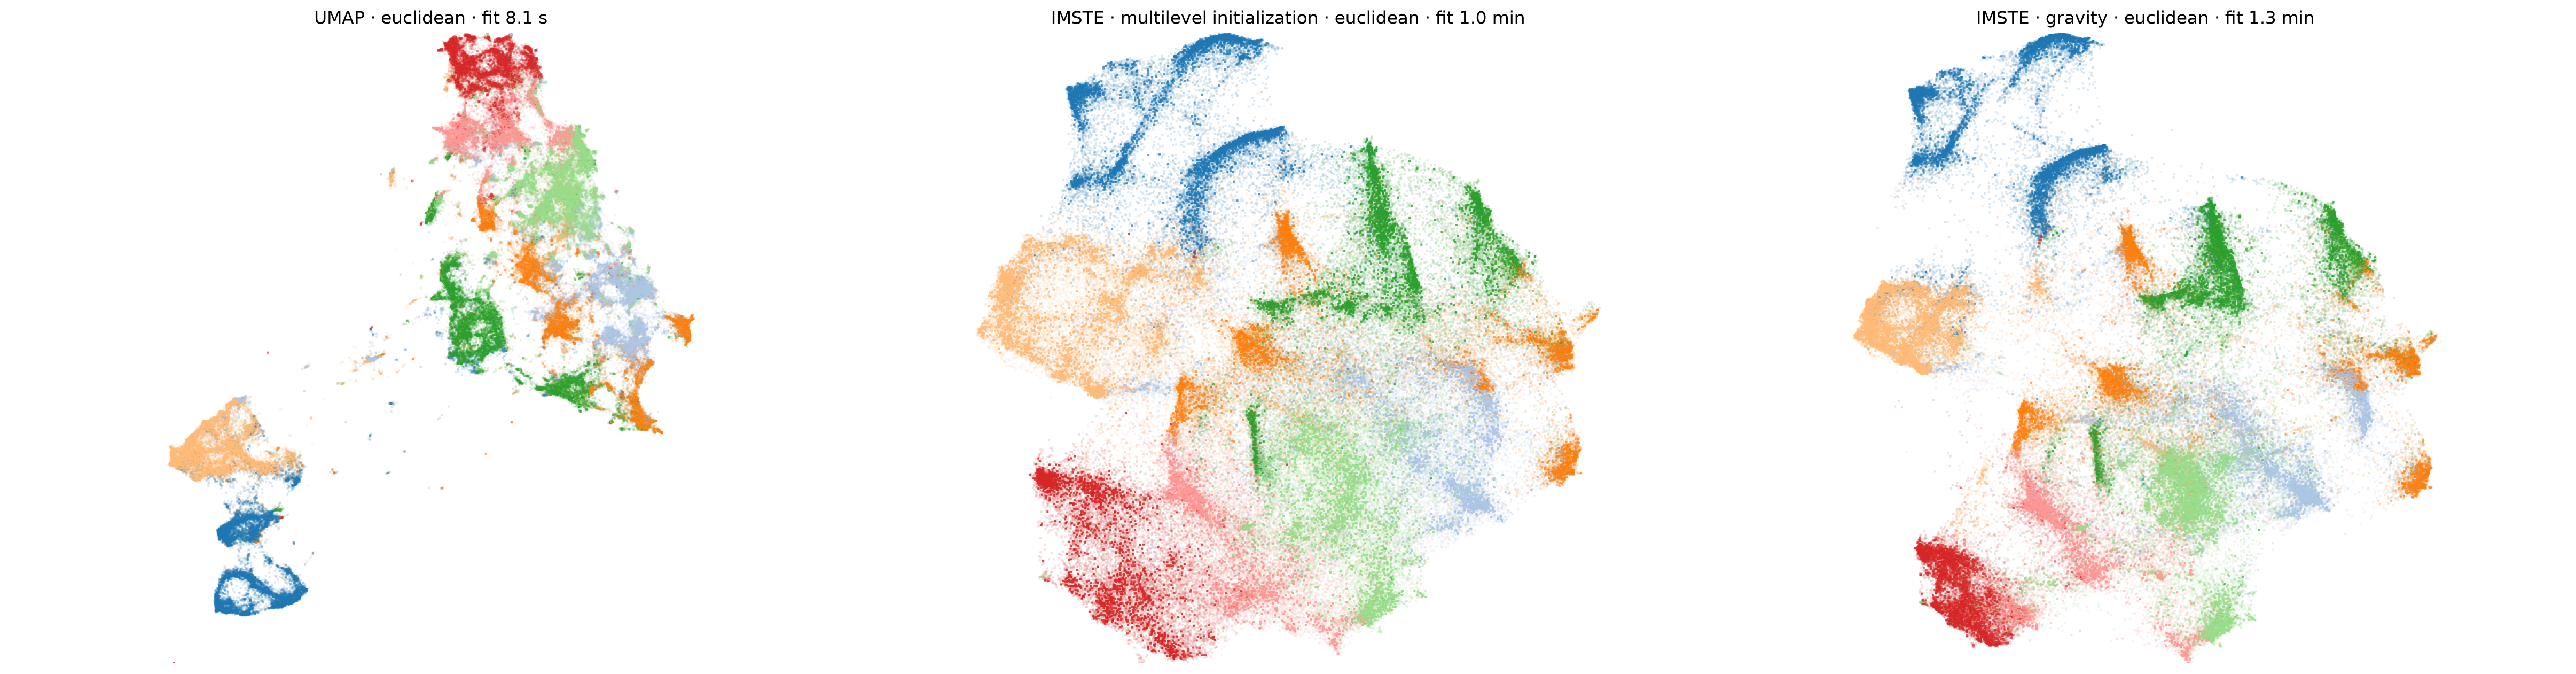

In [44]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
import importlib
import imste.visualization as _imste_visualization
_imste_visualization = importlib.reload(_imste_visualization)
render_datashader_embedding = _imste_visualization.render_datashader_embedding

def render_embedding_preserving_aspect(embedding, labels=None, **kwargs):
    """Render without geometric stretching; support older IMSTE installs too."""
    import inspect
    options = dict(kwargs)
    renderer_parameters = inspect.signature(render_datashader_embedding).parameters
    if "preserve_aspect" in renderer_parameters:
        options["preserve_aspect"] = True
    else:
        coordinates = np.asarray(embedding)
        width = int(options.get("width", 1000))
        height = int(options.get("height", 1000))
        x_limits = np.asarray(
            options.get("x_range") or (coordinates[:, 0].min(), coordinates[:, 0].max()),
            dtype=np.float64,
        )
        y_limits = np.asarray(
            options.get("y_range") or (coordinates[:, 1].min(), coordinates[:, 1].max()),
            dtype=np.float64,
        )
        pixel_scale = max(
            (x_limits[1] - x_limits[0]) / width,
            (y_limits[1] - y_limits[0]) / height,
            np.finfo(np.float64).eps,
        )
        x_center, y_center = float(x_limits.mean()), float(y_limits.mean())
        options["x_range"] = (
            x_center - pixel_scale * width / 2,
            x_center + pixel_scale * width / 2,
        )
        options["y_range"] = (
            y_center - pixel_scale * height / 2,
            y_center + pixel_scale * height / 2,
        )
    return render_datashader_embedding(embedding, labels, **options)


domain_order = list(labels.categories)
palette = plt.get_cmap("tab20")
domain_color_key = {
    domain: to_hex(palette(index % palette.N))
    for index, domain in enumerate(domain_order)
}
label_values = labels.astype(str)
layouts = [
    ("UMAP", Z_umap, umap_seconds),
    ("IMSTE · multilevel initialization", Z_imste_base, imste_seconds),
]
if IMSTE_GRAVITY_ENABLED:
    layouts.append(("IMSTE · gravity", Z_imste, imste_seconds + gravity_seconds))

fig, axes = plt.subplots(1, len(layouts), figsize=(8 * len(layouts), 7), constrained_layout=True, squeeze=False)
for ax, (method, coordinates, seconds) in zip(axes.ravel(), layouts):
    image = render_embedding_preserving_aspect(
        coordinates[:, :2], label_values, width=1200, height=900,
        color_key=domain_color_key, min_alpha=40, background="white",
        spread_px=1,
    )
    ax.imshow(image.to_pil())
    runtime = f"{seconds / 60:.1f} min" if seconds >= 60 else f"{seconds:.1f} s"
    ax.set_title(f"{method} · {METRIC} · fit {runtime}")
    ax.set_axis_off()
display(fig)
plt.close(fig)
